# 01 — Extração da tabela de seções do PAE
> **Estudo educacional independente; não substitui o PAE oficial, a Defesa Civil ou laudo de engenharia.**

**Fonte:** PAE UHE Jurumirim (CTG-SB-PAEE-2026-R0-JUR), prancha CTG-SB-DE-2415-JUR — **página física 38** do PDF (não confundir com a numeração interna do PAE).

Páginas auditadas: 21 (características), 37 (descrição do estudo), 38 (prancha), 52 (vale a jusante), 54-55 (tempo de chegada).

In [1]:
import sys, warnings; warnings.filterwarnings('ignore')
sys.path.insert(0, '../src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
from jurumirim import DISCLAIMER
print(DISCLAIMER)

Estudo educacional independente; não substitui o PAE oficial, a Defesa Civil ou laudo de engenharia.


## 1. Natureza da prancha
A página 38 é uma prancha A1 (2384×1684 pt). A **tabela é texto vetorial**; o **mapa é raster** (41 faixas de imagem).

In [2]:
import pymupdf
from jurumirim.paths import PDF
page = pymupdf.open(PDF)[37]
print(page.rect, 'texto:', len(page.get_text()), 'chars | desenhos vetoriais:', len(page.get_drawings()), '| imagens:', len(page.get_images()))

Rect(0.0, 0.0, 2384.2490234375, 1683.7509765625) texto: 5488 chars | desenhos vetoriais: 1350 | imagens: 45


## 2. Extração por coordenadas
As palavras do PDF são agrupadas por linha (coordenada *y* ao redor de cada ID `ST-xxx`) e ordenadas em *x*. Números BR (`7.432.016`, `29,72`) e `hh:mm` são convertidos; `-` vira `NaN` (nunca adivinhamos valores).

In [3]:
from jurumirim.pae import extract_sections, parse_br_number, hhmm_to_minutes
sec = extract_sections()
sec.drop(columns=['crs','fonte']).round(2)

,id,descricao,distancia_km,x_utm,y_utm,sobrelevacao_m,velocidade_ms,tempo_chegada_hhmm,tempo_chegada_min,vazao_pico_m3s,pagina_fonte_pdf
0,ST-001,Seção da Brecha,0.00,681083.0,7432016.0,29.72,9.46,00:01,1,42728.0,38
1,ST-002,Ponte jusante UHE Jurumirim,0.82,680297.0,7432250.0,28.90,6.92,00:03,3,24017.0,38
2,ST-003,Jusante ponte,1.87,679859.0,7432865.0,28.14,6.39,00:09,9,23278.0,38
3,ST-004,Propriedades MD,3.34,679696.0,7434355.0,28.03,3.68,00:13,13,21500.0,38
4,ST-005,Estreitamento,5.44,678035.0,7434669.0,26.64,4.50,00:21,21,20768.0,38
5,ST-006,Limite da Zona de Autossalvamento,6.71,676911.0,7434574.0,24.85,3.80,00:31,31,20577.0,38
6,ST-007,Propriedades ME,9.78,675349.0,7432642.0,23.62,3.25,00:37,37,20522.0,38
7,ST-008,Estreitamento,11.41,674565.0,7432800.0,21.06,7.38,00:45,45,20426.0,38
8,ST-009,Propriedades ME,13.69,673346.0,7434588.0,18.11,2.04,00:56,56,20304.0,38
9,ST-010,Propriedades ME,16.42,671210.0,7434680.0,16.44,2.67,01:09,69,20199.0,38


## 3. Dupla checagem com a imagem
A prancha foi renderizada e conferida visualmente linha a linha com o texto extraído. Abaixo, o recorte da tabela renderizado do próprio PDF.

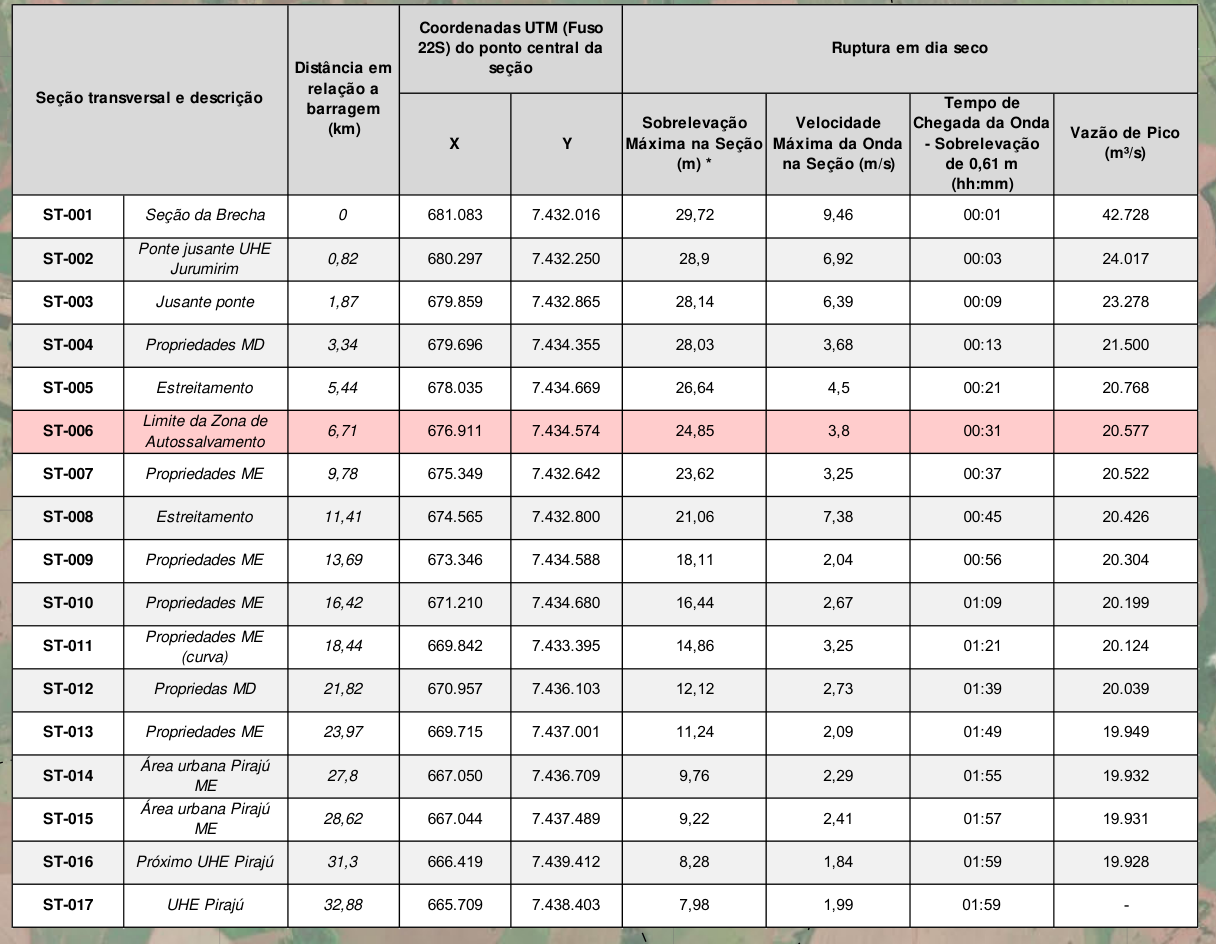

In [4]:
import io
from PIL import Image
pix = page.get_pixmap(matrix=pymupdf.Matrix(1.6,1.6), clip=pymupdf.Rect(1000,130,1760,720))
Image.open(io.BytesIO(pix.tobytes('png')))

In [5]:
# Checagens automáticas de consistência
assert sec.distancia_km.is_monotonic_increasing and sec.tempo_chegada_min.is_monotonic_increasing
assert sec.sobrelevacao_m.is_monotonic_decreasing
print('monotonicidade OK; pendente:', sec[sec.vazao_pico_m3s.isna()].id.tolist(), '(vazão ST-017 = "-" na fonte)')

monotonicidade OK; pendente: ['ST-017'] (vazão ST-017 = "-" na fonte)


## 4. Observações
- 'Propriedas MD' (ST-012) é erro ortográfico da fonte e foi mantido.
- O tempo de chegada refere-se à sobrelevação de **0,61 m (~2 ft)** (nota 2 da prancha).
- Resultado salvo em `data/processed/pae_sections.csv`; procedência em `data/metadata/pae_provenance.json`.